In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving fake reviews dataset.csv to fake reviews dataset.csv


In [ ]:
import pandas as pd

df = pd.read_csv("fake reviews dataset.csv")

print("First 5 rows:")
display(df.head())

print("Column names:")
print(df.columns.tolist())

print("Dataset size (rows, columns):")
print(df.shape)

print("Missing values in each column:")
print(df.isnull().sum())

First 5 rows:


,category,rating,label,text_
0,Home_and_Kitchen_5,5.0,CG,"Love this! Well made, sturdy, and very comfor..."
1,Home_and_Kitchen_5,5.0,CG,"love it, a great upgrade from the original. I..."
2,Home_and_Kitchen_5,5.0,CG,This pillow saved my back. I love the look and...
3,Home_and_Kitchen_5,1.0,CG,"Missing information on how to use it, but it i..."
4,Home_and_Kitchen_5,5.0,CG,Very nice set. Good quality. We have had the s...


Column names:
['category', 'rating', 'label', 'text_']
Dataset size (rows, columns):
(40432, 4)
Missing values in each column:
category    0
rating      0
label       0
text_       0
dtype: int64


In [ ]:
print("Review counts by label:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"\nDataFrame memory usage: {memory_mb:.2f} MB")

Review counts by label:
label
CG    20216
OR    20216
Name: count, dtype: int64

Missing values:
category    0
rating      0
label       0
text_       0
dtype: int64

DataFrame memory usage: 20.26 MB


In [ ]:
print("Review counts by label:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"\nDataFrame memory usage: {memory_mb:.2f} MB")

Review counts by label:
label
CG    20216
OR    20216
Name: count, dtype: int64

Missing values:
category    0
rating      0
label       0
text_       0
dtype: int64

DataFrame memory usage: 20.26 MB


In [ ]:
df["isfake"] = df["label"].map({"OR": 0, "CG": 1})

if df["isfake"].isnull().any():
    raise ValueError("Unexpected label found in the dataset.")

df["original"] = df["text_"].fillna("").astype(str)

display(df[["category", "rating", "label", "isfake", "original"]].head())
print(df["label"].value_counts())

,category,rating,label,isfake,original
0,Home_and_Kitchen_5,5.0,CG,1,"Love this! Well made, sturdy, and very comfor..."
1,Home_and_Kitchen_5,5.0,CG,1,"love it, a great upgrade from the original. I..."
2,Home_and_Kitchen_5,5.0,CG,1,This pillow saved my back. I love the look and...
3,Home_and_Kitchen_5,1.0,CG,1,"Missing information on how to use it, but it i..."
4,Home_and_Kitchen_5,5.0,CG,1,Very nice set. Good quality. We have had the s...


label
CG    20216
OR    20216
Name: count, dtype: int64


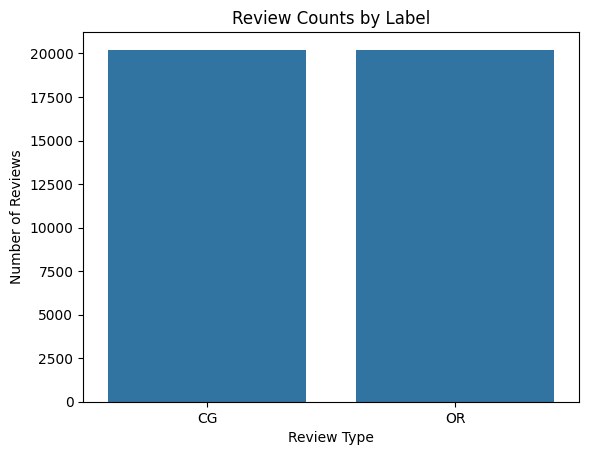

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x="label")
plt.title("Review Counts by Label")
plt.xlabel("Review Type")
plt.ylabel("Number of Reviews")
plt.show()

In [ ]:
for label in ["CG", "OR"]:
    print(f"\nLabel: {label}")
    display(df.loc[df["label"] == label, ["label", "original"]].head(3))


Label: CG


,label,original
0,CG,"Love this! Well made, sturdy, and very comfor..."
1,CG,"love it, a great upgrade from the original. I..."
2,CG,This pillow saved my back. I love the look and...



Label: OR


,label,original
55,OR,"These are just perfect, exactly what I was loo..."
56,OR,Such a great purchase can't beat it for the price
57,OR,What can you say--- cheap and it works as inte...


In [ ]:
import re
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")
stop_words = set(stopwords.words("english"))

def preprocess_review(text):
    text = str(text).lower()
    words = re.findall(r"\b[a-z]{3,}\b", text)
    words = [word for word in words if word not in stop_words]
    return " ".join(words)

df["clean"] = df["original"].fillna("").apply(preprocess_review)

display(df[["original", "clean"]].sample(3, random_state=42))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,original,clean
27957,Eva is on her to find a way to escape her abus...,eva find way escape abusive mother meets hands...
39755,This is my second Glamorise and I love the loo...,second glamorise love look keep bag wardrobe b...
24983,I absolutely love this series. The Ravens are ...,absolutely love series ravens hottest protecti...


In [ ]:
df["clean_word_count"] = df["clean"].str.split().str.len()

print("Total words:", df["clean_word_count"].sum())
print("Unique words:", len(set(" ".join(df["clean"]).split())))
print("Maximum words in one review:", df["clean_word_count"].max())

display(df[["label", "clean", "clean_word_count"]].head())

Total words: 1245495
Unique words: 38035
Maximum words in one review: 283


,label,clean,clean_word_count
0,CG,love well made sturdy comfortable love pretty,7
1,CG,love great upgrade original mine couple years,7
2,CG,pillow saved back love look feel pillow,7
3,CG,missing information use great product price,6
4,CG,nice set good quality set two months,7


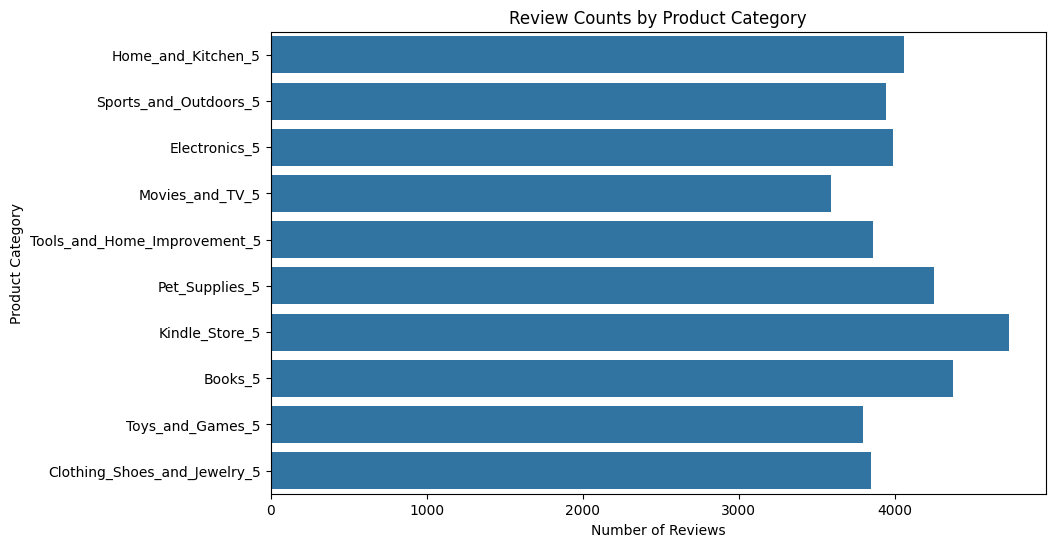

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.countplot(data=df, y="category")
plt.title("Review Counts by Product Category")
plt.xlabel("Number of Reviews")
plt.ylabel("Product Category")
plt.show()

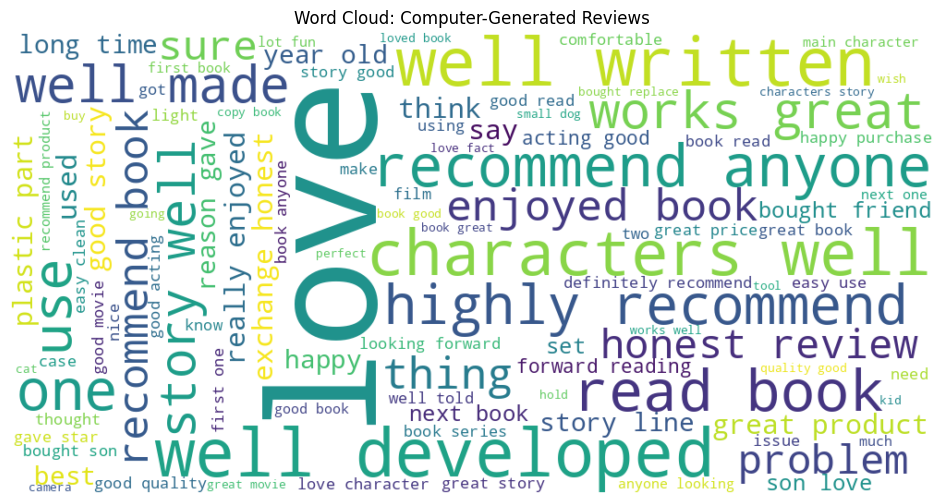

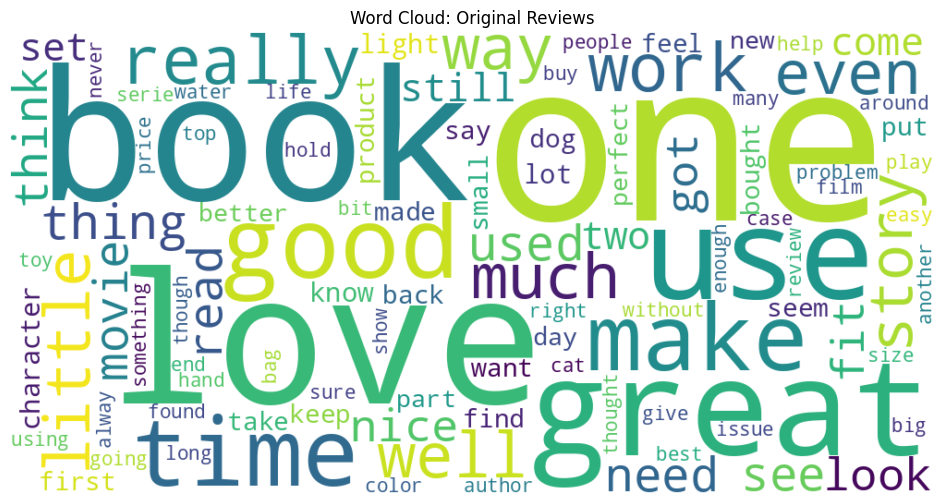

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

for label, label_name in [("CG", "Computer-Generated"), ("OR", "Original")]:
    text = " ".join(df.loc[df["label"] == label, "clean"])

    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color="white",
        max_words=100
    ).generate(text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.title(f"Word Cloud: {label_name} Reviews")
    plt.axis("off")
    plt.show()

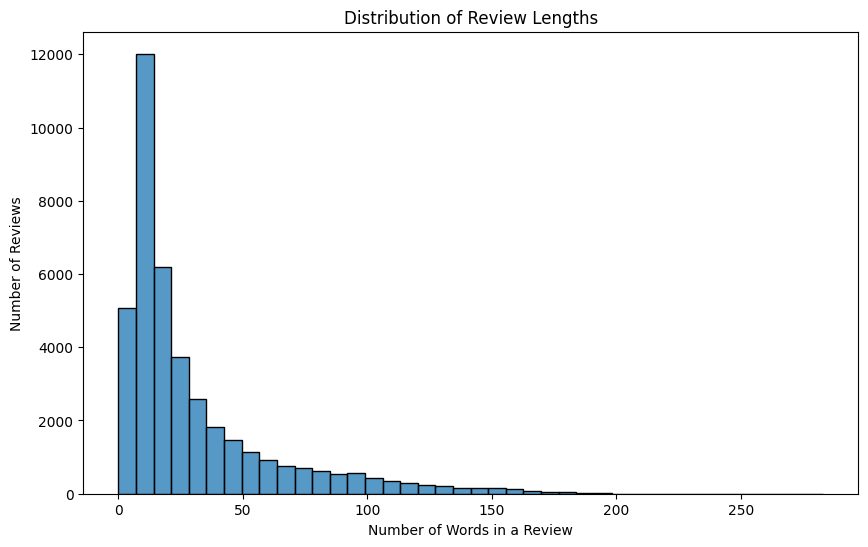

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="clean_word_count", bins=40)
plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words in a Review")
plt.ylabel("Number of Reviews")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X = df["clean"].astype(str)
y = df["isfake"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining label proportions:")
print(y_train.value_counts(normalize=True))
print("\nTesting label proportions:")
print(y_test.value_counts(normalize=True))

Training samples: 32345
Testing samples: 8087

Training label proportions:
isfake
1    0.500015
0    0.499985
Name: proportion, dtype: float64

Testing label proportions:
isfake
0    0.500062
1    0.499938
Name: proportion, dtype: float64


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer

tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

train_sequences = tokenizer.texts_to_sequences(X_train)
test_sequences = tokenizer.texts_to_sequences(X_test)

vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary size:", vocab_size)
print("First review text:")
print(X_train.iloc[0])
print("\nEncoded review:")
print(train_sequences[0][:30])

Vocabulary size: 34379
First review text:
second book series characters story woven together story lot heart second book also filled lot angst something look forward

Encoded review:
[162, 3, 33, 16, 9, 3954, 152, 9, 31, 421, 162, 3, 19, 917, 31, 2636, 180, 82, 174]


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_LEN = 100

X_train_padded = pad_sequences(
    train_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_padded = pad_sequences(
    test_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training data shape:", X_train_padded.shape)
print("Testing data shape:", X_test_padded.shape)
print("\nFirst padded review:")
print(X_train_padded[0])

Training data shape: (32345, 100)
Testing data shape: (8087, 100)

First padded review:
[ 162    3   33   16    9 3954  152    9   31  421  162    3   19  917
   31 2636  180   82  174    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0]


In [ ]:
for max_len in [100, 150, 200]:
    truncated_count = sum(len(sequence) > max_len for sequence in train_sequences)
    truncated_percent = 100 * truncated_count / len(train_sequences)
    print(f"Reviews longer than {max_len} words: {truncated_percent:.2f}%")

Reviews longer than 100 words: 5.53%
Reviews longer than 150 words: 1.05%
Reviews longer than 200 words: 0.03%


In [ ]:
MAX_LEN = 150

X_train_padded = pad_sequences(
    train_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_padded = pad_sequences(
    test_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training data shape:", X_train_padded.shape)
print("Testing data shape:", X_test_padded.shape)

Training data shape: (32345, 150)
Testing data shape: (8087, 150)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, Bidirectional, LSTM, Dense, Dropout

model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=vocab_size, output_dim=64),
    Bidirectional(LSTM(32)),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 150, 64)        │     2,200,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,227,201 (8.50 MB)

 Trainable params: 2,227,201 (8.50 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train_padded,
    y_train,
    validation_split=0.1,
    batch_size=64,
    epochs=3,
    verbose=1
)

Epoch 1/3
455/455 ━━━━━━━━━━━━━━━━━━━━ 73s 150ms/step - accuracy: 0.8433 - loss: 0.3361 - val_accuracy: 0.9082 - val_loss: 0.2136
Epoch 2/3
455/455 ━━━━━━━━━━━━━━━━━━━━ 66s 146ms/step - accuracy: 0.9362 - loss: 0.1647 - val_accuracy: 0.9134 - val_loss: 0.2117
Epoch 3/3
455/455 ━━━━━━━━━━━━━━━━━━━━ 82s 146ms/step - accuracy: 0.9591 - loss: 0.1093 - val_accuracy: 0.9020 - val_loss: 0.2563


Test accuracy: 0.9076
Test loss: 0.2508

                         precision    recall  f1-score   support

          Original (OR)       0.93      0.88      0.91      4044
Computer-Generated (CG)       0.89      0.93      0.91      4043

               accuracy                           0.91      8087
              macro avg       0.91      0.91      0.91      8087
           weighted avg       0.91      0.91      0.91      8087



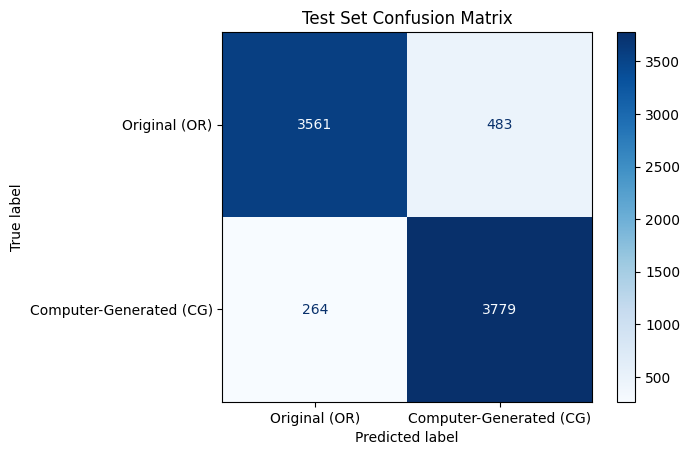

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

test_loss, test_accuracy = model.evaluate(
    X_test_padded,
    y_test,
    verbose=0
)

probabilities = model.predict(X_test_padded, verbose=0).ravel()
predicted_labels = (probabilities >= 0.5).astype(int)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test loss: {test_loss:.4f}")
print()
print(classification_report(
    y_test,
    predicted_labels,
    target_names=["Original (OR)", "Computer-Generated (CG)"],
    zero_division=0
))

confusion = confusion_matrix(y_test, predicted_labels)
display_plot = ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=["Original (OR)", "Computer-Generated (CG)"]
)
display_plot.plot(cmap="Blues", values_format="d")
plt.title("Test Set Confusion Matrix")
plt.show()